# PyTorch GAN on FashionMNIST: Generator + Discriminator


### What's different about a GAN

Everything you've built so far (MLP, CNN classifier, CNN regressor) is trained to take an image
and output *something about* that image (a class, a number). A GAN flips this around: you train
a network — the **Generator** — to take pure random noise and output a *fake image* that looks
like it came from FashionMNIST. It's paired with a second network, the **Discriminator**, whose
job is to tell real training images apart from the Generator's fakes. The two are trained
together, each one improving because the other is getting better:

- **Discriminator** learns: "real FashionMNIST images look like *this*, fakes look like *that*."
- **Generator** learns: "make images good enough to fool the Discriminator."

This adversarial back-and-forth is why it's called a Generative **Adversarial** Network.

Structure:
1. **Part 1 — Build the Generator** (noise vector -> fake image)
2. **Part 2 — Build the Discriminator** (image -> real/fake probability)
3. **Part 3 — The adversarial training loop** (train both networks against each other)
4. **Part 4 — Watch the Generator improve** (sample images at different points in training)


## Setup

Given — just run it. One important difference from your earlier notebook: GAN generators
typically end with a `Tanh` activation, which outputs values in **[-1, 1]**, not [0, 1]. So we
normalize the training images to that same range to match — otherwise the Discriminator could
trivially tell real and fake images apart just by their value range, which teaches it nothing
useful.

In [3]:


import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Normalize to [-1, 1] instead of [0, 1] (mean=0.5, std=0.5 does this for a single channel)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

train_data = torchvision.datasets.FashionMNIST(
    root="./data", train=True, download=True, transform=transform
)

batch_size = 128
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, drop_last=True)

#sanity check of all the formatting

print("Train size:", len(train_data))
print("One image shape:", train_data[0][0].shape, "| value range:",
      train_data[0][0].min().item(), "to", train_data[0][0].max().item())


Using device: cpu
Train size: 60000
One image shape: torch.Size([1, 28, 28]) | value range: -1.0 to 1.0


---
## Part 1 — The Generator

**Goal:** take a vector of random noise and turn it into a 1x28x28 image that (eventually,
after training) looks like a piece of clothing.

**Architecture to build** (a simple fully-connected generator — you already know every layer
type involved from the MLP notebook):
```
Input: random noise vector, shape (batch, latent_dim)   # latent_dim = 64
-> Linear(latent_dim, 128) -> ReLU
-> Linear(128, 256)        -> ReLU
-> Linear(256, 784)        -> Tanh          # squashes output to [-1, 1]
-> reshape to (batch, 1, 28, 28)
```

**Hints:**
- `latent_dim` is just a design choice — a length-64 vector of random numbers is the "seed" the
  Generator uses to produce one image. Different random vectors should produce different images.
- Use `nn.Tanh()` on the *final* layer only — this is what makes the output range match the
  `[-1, 1]`-normalized real images. Using ReLU or no activation on the output would break that
  match, and the Discriminator would learn to exploit the mismatch instead of learning anything
  meaningful about image content.
- After the final `Linear(256, 784)` + `Tanh`, the output is a flat vector of length 784 — use
  `.view(batch_size, 1, 28, 28)` (or `x.view(-1, 1, 28, 28)`) inside `forward` to reshape it back
  into image form.


In [10]:
latent_dim = 64

class Generator(nn.Module):
    def __init__(self, latent_dim=64): # latent_dim defines the dimension of the input noise vector
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Tanh()
        )
        # TODO: define self.net as an nn.Sequential matching the architecture above,
        # ending in Linear(256, 784) -> Tanh (do NOT reshape inside Sequential — do that in forward)

    def forward(self, z):
        x = self.net(z)
        return x.view(x.size(0), 1, 28, 28)  # reshape to (batch, 1, 28, 28) from flat, .view() is a built in function
    # view does not reshape the original tensor but produces a reshaped copy
        



### Noise sampling utility (given)

Every time you want a fake image, you need a fresh random noise vector. This is given since it's
one line, not a learning exercise — but note the shape: `(batch_size, latent_dim)`.

In [11]:
def sample_noise(batch_size, latent_dim=64):
    return torch.randn(batch_size, latent_dim, device=device)

# Sanity check once your Generator TODOs are filled in:
gen = Generator(latent_dim).to(device)
z = sample_noise(4, latent_dim)
fake_imgs = gen(z)
print("Fake image batch shape:", fake_imgs.shape)  # should be (4, 1, 28, 28)


Fake image batch shape: torch.Size([4, 1, 28, 28])


---
## Part 2 — The Discriminator (This is essentially regression with an activation function at the end)

**Goal:** take an image (real or fake) and output a single probability — how likely it is to be
a real FashionMNIST image.

**Architecture to build:**
```
Input: image, shape (batch, 1, 28, 28)
-> Flatten -> 784
-> Linear(784, 256) -> LeakyReLU(0.2)
-> Linear(256, 128) -> LeakyReLU(0.2)
-> Linear(128, 1)   -> Sigmoid          # outputs a probability in [0, 1]
```

**Hints:**
- This looks almost identical to your Part 1 MLP classifier from the earlier notebook, except
  the final layer outputs **1** number (real-vs-fake probability) instead of 10 (class scores),
  and ends in `Sigmoid` instead of raw logits — because here we want an actual probability, not
  logits fed into `CrossEntropyLoss`.
- `nn.LeakyReLU(0.2)` is commonly used instead of plain `ReLU` in GAN discriminators — it allows
  a small negative slope (instead of hard-zeroing negatives) which tends to keep gradients
  flowing better during adversarial training. Worth trying plain `ReLU` too and comparing.
- `nn.Sigmoid()` on the last layer squashes the output to (0, 1) — interpretable directly as
  "probability this image is real."


In [ ]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            # nn.sequential automatically implements .requires_grad()
            nn.Flatten(),  # flatten the image to (batch, 784)
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 128),
            nn.LeakyReLU(0.2),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

    def forward(self, img):
        # TODO: pass img through self.net and return the result (shape (batch, 1))

        x = self.net(img)
        return x


# need to flatte before sequantial

In [18]:
# Sanity check once your Discriminator TODOs are filled in:
disc = Discriminator().to(device)
real_batch, _ = next(iter(train_loader))
real_batch = real_batch.to(device)
preds = disc(real_batch)
print("Discriminator output shape:", preds.shape)  # should be (batch_size, 1)
print("Sample outputs (should be in [0,1]):", preds[:5].detach().cpu().view(-1))


Discriminator output shape: torch.Size([128, 1])
Sample outputs (should be in [0,1]): tensor([0.4976, 0.5101, 0.4942, 0.4853, 0.5042])


---
## Part 3 — The adversarial training loop

This is the core of a GAN, and it's structurally different from anything you've trained so
far: **two networks, two optimizers, two losses, trained back-to-back on the same batch.**

### The loss function: Binary Cross-Entropy

Both networks are ultimately trained with `nn.BCELoss()` — appropriate here because the
Discriminator's job is genuinely **binary classification** (real vs. fake), and it outputs a
probability via `Sigmoid` (matching what `BCELoss` expects, unlike `CrossEntropyLoss` which wants
raw logits over multiple classes).

### Step A — Train the Discriminator on one batch

Construction guide:
1. Get a batch of real images from `train_loader` (ignore the label — GANs don't use it).
2. Compute the Discriminator's loss on **real** images: run them through `disc`, compare the
   output to a target of all **1s** (label "real") using `BCELoss`.
3. Sample fresh noise with `sample_noise(...)`, generate a batch of **fake** images with `gen`.
   Important: wrap this in `.detach()` (e.g. `gen(z).detach()`) so gradients don't flow back into
   the Generator during the Discriminator's update step — at this point you only want to update
   the Discriminator.
4. Compute the Discriminator's loss on these fake images: run them through `disc`, compare the
   output to a target of all **0s** (label "fake").
5. Add the real-image loss and fake-image loss together to get the total Discriminator loss.
6. Standard training step on that total loss: zero the Discriminator's optimizer gradients,
   `.backward()`, step the Discriminator's optimizer only.

### Step B — Train the Generator on one batch

Construction guide:
1. Sample a **new** batch of noise, generate fake images with `gen` (this time *without*
   `.detach()` — you need gradients to flow back into the Generator).
2. Run these fake images through `disc` to get its predictions.
3. Here's the adversarial trick: compute the Generator's loss by comparing the Discriminator's
   output to a target of all **1s** — i.e., the Generator is rewarded when it fools the
   Discriminator into predicting "real." (Not 0s — the Generator wants the *opposite* of what the
   Discriminator is trying to achieve.)
4. Standard training step: zero the Generator's optimizer gradients, `.backward()`, step the
   Generator's optimizer only.

**Important:** each network has its **own separate optimizer**, and each step only updates its
own network's parameters. Mixing these up (e.g. accidentally stepping both optimizers on the same
loss) is the most common GAN bug.


In [22]:

gen = Generator().to(device)
disc = Discriminator().to(device)

loss_fn = nn.BCELoss()


gen_optimizer = torch.optim.Adam(gen.parameters(), lr=2e-4, betas=(0.5, 0.999))
disc_optimizer = torch.optim.Adam(disc.parameters(), lr=2e-4, betas=(0.5, 0.999))


# gen.parameters() or disc.parameyers() signifies an iterator that walks through each of the tensors correspoding to sequential layers



In [23]:
def train_one_epoch_gan(gen, disc, loader, gen_optimizer, disc_optimizer, loss_fn, latent_dim=64):
    gen.train()
    disc.train()
    total_gen_loss = 0.0
    total_disc_loss = 0.0

    for real_imgs, _ in loader:

        real_imgs = real_imgs.to(device)
        batch_size = real_imgs.size(0)

        real_labels = torch.ones(batch_size, 1, device=device)
        fake_labels = torch.zeros(batch_size, 1, device=device)

        # train the Discriminator 
        disc_optimizer.zero_grad()

        real_preds = disc(real_imgs)
        loss_real = loss_fn(real_preds, real_labels)

        z = sample_noise(batch_size, latent_dim)
        fake_imgs = gen(z).detach()  # detach: don't backprop into the Generator here
        fake_preds = disc(fake_imgs)
        loss_fake = loss_fn(fake_preds, fake_labels)

        disc_loss = loss_real + loss_fake
        disc_loss.backward()
        disc_optimizer.step()

        # train the Generator
        gen_optimizer.zero_grad()

        z = sample_noise(batch_size, latent_dim)
        fake_imgs = gen(z)  # no detach: gradients must flow back into gen
        fake_preds = disc(fake_imgs)
        gen_loss = loss_fn(fake_preds, real_labels)  # want disc fooled into predicting "real"

        gen_loss.backward()
        gen_optimizer.step()

        total_disc_loss += disc_loss.item() * batch_size
        total_gen_loss += gen_loss.item() * batch_size


    
    n = len(loader.dataset)
    print(f"Average Generator loss: {total_gen_loss / n:.4f}, Average Discriminator loss: {total_disc_loss / n:.4f}")
    return total_gen_loss / n, total_disc_loss / n


### Run training

A GAN's loss values don't behave like a classifier's — they don't necessarily converge to a
small number. A "healthy" run usually shows both losses oscillating and staying roughly balanced
in the same ballpark, rather than one collapsing to near-zero while the other explodes (that
usually signals one network overpowered the other). Judge progress mainly by looking at the
generated *images* (Part 4), not just the loss numbers.

GANs typically need more epochs than the classifiers you trained earlier — start with something
like 20-30 and watch the sample grid evolve.

In [25]:
n_epochs = 20
for epoch in range(n_epochs):
    print(f"Epoch {epoch+1}\n-------------------------------")
    train_one_epoch_gan(
        gen, disc, train_loader, gen_optimizer, disc_optimizer, loss_fn, latent_dim
    )
    


Epoch 1
-------------------------------
Average Generator loss: 2.0246, Average Discriminator loss: 0.5233
Epoch 2
-------------------------------
Average Generator loss: 2.5146, Average Discriminator loss: 0.5243
Epoch 3
-------------------------------
Average Generator loss: 2.3749, Average Discriminator loss: 0.6260
Epoch 4
-------------------------------
Average Generator loss: 2.2273, Average Discriminator loss: 0.6702
Epoch 5
-------------------------------
Average Generator loss: 2.4061, Average Discriminator loss: 0.6102
Epoch 6
-------------------------------
Average Generator loss: 2.5084, Average Discriminator loss: 0.6260
Epoch 7
-------------------------------
Average Generator loss: 2.3755, Average Discriminator loss: 0.6728
Epoch 8
-------------------------------
Average Generator loss: 2.4356, Average Discriminator loss: 0.6352
Epoch 9
-------------------------------
Average Generator loss: 2.4544, Average Discriminator loss: 0.6347
Epoch 10
----------------------------

---
## Part 4 — Watch the Generator improve

Generates a grid of fake images from fresh random noise so you can see what
the Generator has learned to produce. Images remap from [-1, 1] back to [0, 1] for display.

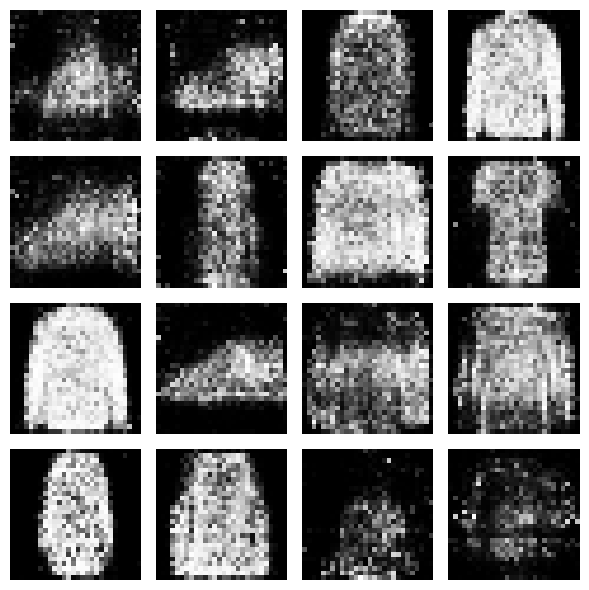

In [26]:
gen.eval()
with torch.no_grad():
    z = sample_noise(16, latent_dim)
    samples = gen(z).cpu()
    samples = (samples + 1) / 2  # undo the [-1, 1] normalization for display

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i].squeeze(), cmap="gray")
    ax.axis("off")
plt.tight_layout()
plt.show()


# Conditional GAN

Define som